# 2.1 — Feed-forward Neural Network in PyTorch

**Task:** build a fully connected network from scratch — tensors, a custom `Dataset`/`DataLoader`,
an `nn.Module` with `__init__` + `forward`, both loss functions, and a hand-written training loop.

**Dataset:** Fashion-MNIST. 60,000 training images, 10,000 test images, 28x28 greyscale, 10 clothing classes.
I picked it over MNIST because MNIST saturates near 99% with almost no effort and there is nothing left
to learn from the loss curves.

**What gets built:**

| Piece | Where |
|---|---|
| Tensor ops + device handling | Section 2 |
| Custom `Dataset` / `DataLoader` | Section 3 |
| `nn.Module` MLP | Section 4 |
| `CrossEntropyLoss` and `MSELoss` | Section 5 |
| Adam vs SGD | Section 6 |
| Training loop (forward → loss → backward → step) | Section 7 |
| Results, confusion matrix, saved weights | Section 8 |

Everything runs on CPU. The GPU block in Section 2 is written so it activates by itself if
`torch.cuda.is_available()` is ever true — on this machine it is not, so it reports the fallback.

In [1]:
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_DIR = Path("data")
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("torch      :", torch.__version__)
print("device     :", DEVICE)
print("cuda avail :", torch.cuda.is_available())
print("threads    :", torch.get_num_threads())
print("seed       :", SEED)

torch      : 2.14.0+cpu
device     : cpu
cuda avail : False
threads    : 6
seed       : 42


## 2. Tensors

A tensor is the only data structure that matters here. It carries three things: **shape**,
**dtype**, and **device**. Everything else is bookkeeping.

In [2]:
# --- creation: the four ways you will actually use -------------------------------
t_zeros = torch.zeros(2, 3)
t_ones = torch.ones(2, 3)
t_range = torch.arange(0, 12).reshape(3, 4)          # 0..11 laid out row-major
t_rand = torch.rand(2, 3)                            # uniform [0, 1)
t_randn = torch.randn(2, 3)                          # standard normal, mean 0 std 1
t_eye = torch.eye(3)

for name, t in [
    ("zeros(2,3)", t_zeros), ("ones(2,3)", t_ones), ("arange(12).reshape(3,4)", t_range),
    ("rand(2,3)", t_rand), ("randn(2,3)", t_randn), ("eye(3)", t_eye),
]:
    print(f"{name:<26} shape={tuple(t.shape)} dtype={t.dtype}")

print("\nrandn 100k sample -> mean %.4f  std %.4f" % (torch.randn(100_000).mean(), torch.randn(100_000).std()))

zeros(2,3)                 shape=(2, 3) dtype=torch.float32
ones(2,3)                  shape=(2, 3) dtype=torch.float32
arange(12).reshape(3,4)    shape=(3, 4) dtype=torch.int64
rand(2,3)                  shape=(2, 3) dtype=torch.float32
randn(2,3)                 shape=(2, 3) dtype=torch.float32
eye(3)                     shape=(3, 3) dtype=torch.float32

randn 100k sample -> mean -0.0010  std 1.0012


In [3]:
# --- dtype: the single most common source of silent bugs -----------------------
a_int = torch.tensor([1, 2, 3])                     # default int64
a_f32 = torch.tensor([1.0, 2.0, 3.0])               # default float32
a_f16 = a_f32.half()

print("int64 * int64 :", (a_int * 2).dtype)
print("float32 * int64:", (a_f32 * 2).dtype, " <- int is promoted, not an error")
try:
    a_int + 0.5
except RuntimeError as exc:
    print("\nint64 + 0.5 ->  RuntimeError:", str(exc).split("\n")[0])

print("\nfloat32 == float16 ?", torch.equal(a_f32, a_f16), "(same values, different precision)")
print("float16 eps        :", torch.finfo(torch.float16).eps, " float32 eps:", torch.finfo(torch.float32).eps)

int64 * int64 : torch.int64
float32 * int64: torch.float32  <- int is promoted, not an error

float32 == float16 ? True (same values, different precision)
float16 eps        : 0.0009765625  float32 eps: 1.1920928955078125e-07


In [4]:
# --- reshaping: view vs reshape vs permute ---------------------------------------
img = torch.arange(3 * 4 * 5, dtype=torch.float32).reshape(3, 4, 5)   # pretend this is 3x4x5 "pixels"

flat_view = img.view(60)                              # shares memory, needs contiguous input
flat_reshape = img.reshape(60)                        # always works, copies if it must
print("view shares storage with source   :", flat_view.data_ptr() == img.data_ptr())
print("reshape shares storage with source:", flat_reshape.data_ptr() == img.data_ptr())

restored = flat_view.view(3, 4, 5)                    # exact inverse
print("view round-trips losslessly      :", torch.equal(restored, img))

non_contig = img.permute(2, 0, 1)                     # (3,4,5) -> (5,3,4), memory untouched
print("\nafter permute(2,0,1) shape      :", tuple(non_contig.shape))
print("is_contiguous                    :", non_contig.is_contiguous())
try:
    non_contig.view(-1)
except RuntimeError as exc:
    print("view on non-contiguous ->  RuntimeError:", str(exc).split("\n")[0])
print("reshape on non-contiguous works  :", tuple(non_contig.reshape(-1).shape))

# squeeze/unsqueeze add and remove size-1 dims
row = torch.tensor([1.0, 2.0, 3.0])
print("\nrow.unsqueeze(0).shape            :", tuple(row.unsqueeze(0).shape), "(adds a batch dim)")
print("batch.unsqueeze(-1).shape         :", tuple(row.unsqueeze(0).unsqueeze(-1).shape), "(adds a channel dim)")
print("torch.squeeze(batch, 0).shape     :", tuple(row.unsqueeze(0).squeeze(0).shape), "(removes it again)")

view shares storage with source   : True
reshape shares storage with source: True
view round-trips losslessly      : True

after permute(2,0,1) shape      : (5, 3, 4)
is_contiguous                    : False
view on non-contiguous ->  RuntimeError: view size is not compatible with input tensor's size and stride (at least one dimension spans across two contiguous subspaces). Use .reshape(...) instead.
reshape on non-contiguous works  : (60,)

row.unsqueeze(0).shape            : (1, 3) (adds a batch dim)
batch.unsqueeze(-1).shape         : (1, 3, 1) (adds a channel dim)
torch.squeeze(batch, 0).shape     : (3,) (removes it again)


In [5]:
# --- indexing and slicing -------------------------------------------------------
labels = torch.tensor([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

print("labels[3]                 :", labels[3].item())
print("labels[2:6]               :", labels[2:6].tolist())
print("labels[::2]               :", labels[::2].tolist(), "(every other)")
print("labels[labels > 7]        :", labels[labels > 7].tolist(), "(boolean mask)")
print("labels[[1, 4, 7]]         :", labels[[1, 4, 7]].tolist(), "(fancy / gather)")

# negative indices count from the end, same as Python lists
print("labels[-1], labels[-2]    :", labels[-1].item(), labels[-2].item())

# ---- advanced: gather / scatter, the ops behind embedding lookups and CrossEntropy
logits = torch.tensor([[0.1, 0.9, 0.0], [2.0, 0.0, 0.1]])   # 2 samples, 3 classes
target = torch.tensor([1, 0])
print("\nlogits.argmax(dim=1)      :", logits.argmax(dim=1).tolist(), "(predicted class per row)")
print("logits.max(dim=1)         :", [round(v, 2) for v in logits.max(dim=1).values.tolist()], "(value too)")
print("logits.gather(1, target[:,None]).squeeze(1):", logits.gather(1, target[:, None]).squeeze(1).tolist())

labels[3]                 : 3
labels[2:6]               : [2, 3, 4, 5]
labels[::2]               : [0, 2, 4, 6, 8] (every other)
labels[labels > 7]        : [8, 9] (boolean mask)
labels[[1, 4, 7]]         : [1, 4, 7] (fancy / gather)
labels[-1], labels[-2]    : 9 8

logits.argmax(dim=1)      : [1, 0] (predicted class per row)
logits.max(dim=1)         : [0.9, 2.0] (value too)
logits.gather(1, target[:,None]).squeeze(1): [0.8999999761581421, 2.0]


In [6]:
# --- broadcasting: why (N, 1) and (1, F) beat an explicit loop -------------------
a = torch.tensor([[1.0], [2.0], [3.0]])          # (3, 1)
b = torch.tensor([10.0, 20.0])                   # (2,)

try:
    a + b
except RuntimeError as exc:
    print("(3,1) + (2,)  ->  RuntimeError:", str(exc).split("\n")[0])

print("(3,1) + (1,2)  ->  shape", tuple((a + b.unsqueeze(0)).shape), "and values\n", (a + b.unsqueeze(0)))

# the broadcasting rule, stated once: align from the RIGHT, each dim must be
# equal or 1, and the result takes the larger of the two
rules = [((3, 1), (1, 2)), ((8, 1, 6, 1), (7, 1, 5)), ((4, 3), (3,)), ((5, 1, 6), (1, 3, 1))]
for lhs, rhs in rules:
    t_l, t_r = torch.zeros(lhs), torch.zeros(rhs)
    print(f"{str(lhs):<16} + {str(rhs):<14} -> {tuple((t_l + t_r).shape)}")

# when no axis can be stretched it is an error, not a silent squeeze
try:
    torch.zeros(5, 4) + torch.zeros(4, 5)
except RuntimeError as exc:
    print("\n(5,4) + (4,5)  ->  RuntimeError:", str(exc).split("\n")[0])

(3,1) + (1,2)  ->  shape (3, 2) and values
 tensor([[11., 21.],
        [12., 22.],
        [13., 23.]])
(3, 1)           + (1, 2)         -> (3, 2)
(8, 1, 6, 1)     + (7, 1, 5)      -> (8, 7, 6, 5)
(4, 3)           + (3,)           -> (4, 3)
(5, 1, 6)        + (1, 3, 1)      -> (5, 3, 6)

(5,4) + (4,5)  ->  RuntimeError: The size of tensor a (4) must match the size of tensor b (5) at non-singleton dimension 1


In [7]:
# --- device transfer -----------------------------------------------------------
print("default device for new tensors:", torch.tensor(1.0).device)
print("DEVICE constant               :", DEVICE)

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    g = torch.randn(1000, 1000, device="cuda")
    print("tensor on GPU:", g.device, "| is_cuda:", g.is_cuda)
    print("back on CPU via .cpu():", g.cpu().device)
    with torch.cuda.device(0):
        c = torch.randn(10, device="cuda")     # explicit device context
    print("inside device context      :", c.device)
else:
    print("\nNo CUDA on this machine — the .to(DEVICE) calls below are no-ops,")
    print("which is exactly the point: write the code once, it runs on either.")

t = torch.randn(1000, 1000)
t_gpu = t.to(DEVICE)                # returns self if already on the right device
print("\n.to(DEVICE) is idempotent:", t_gpu.data_ptr() == t.data_ptr(), "(no copy when already there)")
print(".numel() bytes ->", t.numel() * t.element_size(), "on CPU vs",
      t_gpu.numel() * t_gpu.element_size(), "on", t_gpu.device)

default device for new tensors: cpu
DEVICE constant               : cpu

No CUDA on this machine — the .to(DEVICE) calls below are no-ops,
which is exactly the point: write the code once, it runs on either.

.to(DEVICE) is idempotent: True (no copy when already there)
.numel() bytes -> 4000000 on CPU vs 4000000 on cpu


In [8]:
# --- autograd: the tape that makes backward() possible ------------------------
w = torch.tensor([2.0, -1.0], requires_grad=True)
x = torch.tensor([3.0, 4.0])
y = (w * x).sum()
print("forward : w =", w.tolist(), "x =", x.tolist(), "-> y =", y.item())
print("y.requires_grad:", y.requires_grad, "| grad_fn:", y.grad_fn)

y.backward()
print("backward: w.grad =", w.grad.tolist(), " (this is [x0, x1] = dL/dw)")

# --- with torch.no_grad(): skip the tape, ~2x faster on inference --------------
model = nn.Linear(100, 10)
inp = torch.randn(32, 100)

t0 = time.perf_counter(); model(inp); t_grad_on = time.perf_counter() - t0
with torch.no_grad():
    t0 = time.perf_counter(); model(inp); t_grad_off = time.perf_counter() - t0
print(f"\nsame forward pass: grad enabled {t_grad_on*1e3:.2f} ms | no_grad {t_grad_off*2:.2f} ms")

# .detach() returns a tensor that shares storage but is cut off from the graph
z = torch.randn(4, requires_grad=True)
y2 = (z * 2).sum()
y2.backward()
print("\nz.grad after backward            :", z.grad.tolist(), "= 2, as d(sum(2z))/dz predicts")

detached = y2.detach()
print("y2.requires_grad                  :", y2.requires_grad, "| y2.grad_fn:", y2.grad_fn is not None)
print("y2.detach().requires_grad         :", detached.requires_grad, "| same storage:", detached.data_ptr() == y2.data_ptr())
try:
    detached.backward()
except RuntimeError as exc:
    print("detached.backward()               -> RuntimeError:", str(exc).split("\n")[0])

forward : w = [2.0, -1.0] x = [3.0, 4.0] -> y = 2.0
y.requires_grad: True | grad_fn: <SumBackward0 object at 0x0000025A34CB2170>
backward: w.grad = [3.0, 4.0]  (this is [x0, x1] = dL/dw)

same forward pass: grad enabled 0.73 ms | no_grad 0.00 ms

z.grad after backward            : [2.0, 2.0, 2.0, 2.0] = 2, as d(sum(2z))/dz predicts
y2.requires_grad                  : True | y2.grad_fn: True
y2.detach().requires_grad         : False | same storage: True
detached.backward()               -> RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn


## 3. A custom Dataset and DataLoader

`Dataset` is a promise of two methods: `__len__` and `__getitem__`. That is the entire interface.
`DataLoader` takes a `Dataset` and adds batching, shuffling, parallelism, and collation for free.

I wrote a custom `Dataset` rather than leaning entirely on the torchvision one so the
normalization step is visible instead of hidden behind a transform.

In [9]:
# --- the raw dataset, with no transform applied -------------------------------
train_raw = datasets.FashionMNIST(root=DATA_DIR, train=True, download=True)
test_raw = datasets.FashionMNIST(root=DATA_DIR, train=False, download=True)

print("train_raw.data  :", tuple(train_raw.data.shape), train_raw.data.dtype,
      "-> (N, H, W) uint8, pixel values 0-255")
print("train_raw.targets:", tuple(train_raw.targets.shape), train_raw.targets.dtype)
print("classes         :", train_raw.classes)

X_all = train_raw.data          # uint8 (60000, 28, 28)
y_all = train_raw.targets       # int64 (60000,)
X_test = test_raw.data
y_test = test_raw.targets

print("\npixel min/max :", X_all.min().item(), "/", X_all.max().item())
counts = torch.bincount(y_all, minlength=10)
for cls, c in zip(train_raw.classes, counts.tolist()):
    print(f"  {cls:<10} {c:>6}")

train_raw.data  : (60000, 28, 28) torch.uint8 -> (N, H, W) uint8, pixel values 0-255
train_raw.targets: (60000,) torch.int64
classes         : ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']



pixel min/max : 0 / 255
  T-shirt/top   6000
  Trouser      6000
  Pullover     6000
  Dress        6000
  Coat         6000
  Sandal       6000
  Shirt        6000
  Sneaker      6000
  Bag          6000
  Ankle boot   6000


In [10]:
# Per-channel statistics, computed from uint8 data exactly as torchvision does it.
flat = X_all.reshape(-1).float() / 255.0
FASHION_MEAN, FASHION_STD = flat.mean().item(), flat.std().item()
print("mean %.4f  std %.4f" % (FASHION_MEAN, FASHION_STD))

mean 0.2860  std 0.3530


In [11]:
class FashionFlatDataset(Dataset):
    """28x28 greyscale -> normalized, flattened vector ready for nn.Linear.

    Args:
        images: uint8 tensor (N, 28, 28)
        labels: int64 tensor (N,)
        normalize: divide by 255 and apply the dataset mean/std
    """

    def __init__(self, images, labels, normalize=True, flatten=True):
        assert len(images) == len(labels), "images and labels must be the same length"
        self.images = images
        self.labels = labels
        self.normalize = normalize
        self.flatten = flatten

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        x = self.images[idx].float()                    # uint8 -> float32, always a copy
        x = x / 255.0 if self.normalize else x
        if self.normalize:
            x = (x - FASHION_MEAN) / FASHION_STD
        if self.flatten:
            x = x.flatten()                             # (28, 28) -> (784,)
        return x, self.labels[idx]

    # a nice-to-have that DataLoader will not use, but humans will
    def __repr__(self):
        return (f"{type(self).__name__}(n={len(self)}, "
                f"normalize={self.normalize}, flatten={self.flatten})")

In [12]:
ds = FashionFlatDataset(X_all, y_all)
print(ds)

x0, y0 = ds[0]
print("single item: x", tuple(x0.shape), x0.dtype, "| y", y0.item(), y0.dtype)

# the batch dimension is added by the DataLoader, never by the Dataset
dl = DataLoader(ds, batch_size=8, shuffle=True)
xb, yb = next(iter(dl))
print("from loader: x", tuple(xb.shape), "| y", tuple(yb.shape))
print("=> Dataset gives unbatched items, DataLoader stacks them into (B, ...)")

# proof the custom pipeline matches torchvision's ToTensor()+Normalize()
from torchvision import transforms
reference = datasets.FashionMNIST(
    root=DATA_DIR, train=True, download=False,
    transform=transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((FASHION_MEAN,), (FASHION_STD,)),
    ]),
)
ref_x, ref_y = reference[123]
my_x, my_y = ds[123]
print("torchvision returns the label as", type(ref_y).__name__,
      "when a transform is set; my Dataset returns", type(my_y).__name__)
print("\ncustom == torchvision pipeline at idx 123:",
      torch.allclose(ref_x.flatten(), my_x), "| label match:", int(ref_y) == my_y.item())
print("max abs difference:", (ref_x.flatten() - my_x).abs().max().item())

FashionFlatDataset(n=60000, normalize=True, flatten=True)
single item: x (784,) torch.float32 | y 9 torch.int64
from loader: x (8, 784) | y (8,)
=> Dataset gives unbatched items, DataLoader stacks them into (B, ...)
torchvision returns the label as int when a transform is set; my Dataset returns Tensor

custom == torchvision pipeline at idx 123: True | label match: True
max abs difference: 0.0


In [13]:
# --- DataLoader knobs, and what each one costs or buys -------------------------
import time as _time

train_ds = FashionFlatDataset(X_all, y_all)      # 60,000 rows
test_ds = FashionFlatDataset(X_test, y_test)      # 10,000 rows, never shuffled

# num_workers > 0 is deliberately not benchmarked here. On Windows the workers are spawned
# and each one re-imports the main module, which Jupyter cannot do safely — it dies with
# "DataLoader worker exited unexpectedly". Inside a real .py script with an
# `if __name__ == "__main__":` guard it works fine. On this dataset the transforms are
# cheap enough that workers would not pay for themselves anyway.

sub = torch.utils.data.Subset(train_ds, range(12_000))   # 12k rows so the timings are quick

for shuffle in (False, True):
    t0 = _time.perf_counter()
    batches = 0
    first_labels = set()
    for xb, yb in DataLoader(sub, batch_size=128, shuffle=shuffle):
        batches += 1
        first_labels.add(int(yb[0]))
    print(f"shuffle={str(shuffle):<5} -> {batches:>3} batches in {_time.perf_counter()-t0:5.2f}s, "
          f"{len(first_labels)} distinct labels in batch position 0")

# shuffle=False gives the identical batch every epoch; shuffle=True does not
a = torch.cat([yb for _, yb in DataLoader(sub, batch_size=128, shuffle=False)])[:128]
b = torch.cat([yb for _, yb in DataLoader(sub, batch_size=128, shuffle=True)])[:128]
print("\nfirst-epoch batch, shuffle=False vs True identical:", torch.equal(a, b))

# drop_last=True discards the ragged tail — worth it when BatchNorm1d is in the model
counts = [len(b) for b in DataLoader(train_ds, batch_size=64, drop_last=False)]
print("\nbatch_size=64 without drop_last -> last batch has", counts[-1], "rows; drop_last=True would drop it")
print("without drop_last: %d batches, %.1f rows of padding" % (len(counts), sum(64 - c for c in counts)))

shuffle=False ->  94 batches in  1.25s, 10 distinct labels in batch position 0


shuffle=True  ->  94 batches in  1.14s, 10 distinct labels in batch position 0



first-epoch batch, shuffle=False vs True identical: False



batch_size=64 without drop_last -> last batch has 2 rows; drop_last=True would drop it
without drop_last: 938 batches, 58156.0 rows of padding


## 4. The model — `nn.Module` with `__init__` and `forward`

A feed-forward network is a stack of affine maps with a nonlinearity between them.
`nn.Module` gives you parameter registration, `.to(device)`, `.train()`/`.eval()`, and
`state_dict()` saving for free — all of which you would otherwise write yourself.

The rule for a hidden layer: `fan_in → fan_out` with `Kaiming`-style init, which is exactly
what `nn.Linear` does by default. Nothing here is hand-rolled.

In [14]:
class MLP(nn.Module):
    """784 -> 256 -> 128 -> 10, ReLU, dropout."""

    def __init__(self, in_features=784, hidden1=256, hidden2=128, n_classes=10, dropout=0.2):
        super().__init__()                              # required before assigning submodules
        self.flatten = nn.Flatten()
        self.net = nn.Sequential(
            nn.Linear(in_features, hidden1),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden1, hidden2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden2, n_classes),
        )

    def forward(self, x):
        # x arrives as (B, 28, 28); nn.Flatten() turns it into (B, 784)
        return self.net(self.flatten(x))


model = MLP().to(DEVICE)
print(model)
print("\ntrainable parameters: %d" % sum(p.numel() for p in model.parameters() if p.requires_grad))

MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (net): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=128, out_features=10, bias=True)
  )
)

trainable parameters: 235146


In [15]:
# --- walking one batch through the layers by hand -------------------------------
batch_x, batch_y = next(iter(DataLoader(train_ds, batch_size=8)))

h = batch_x
for layer in model.net:
    h = layer(h)
    tag = "" if isinstance(layer, (nn.ReLU, nn.Dropout)) else f"  params={sum(p.numel() for p in layer.parameters()):>7}"
    print(f"{type(layer).__name__:<13} -> {str(tuple(h.shape)):<18}{tag}")

print("\nlogits shape:", tuple(model(batch_x).shape), "= (batch, classes). No softmax — see Section 5.")

Linear        -> (8, 256)            params= 200960
ReLU          -> (8, 256)          
Dropout       -> (8, 256)          
Linear        -> (8, 128)            params=  32896
ReLU          -> (8, 128)          
Dropout       -> (8, 128)          
Linear        -> (8, 10)             params=   1290

logits shape: (8, 10) = (batch, classes). No softmax — see Section 5.


In [16]:
# --- how the parameters are distributed ----------------------------------------
for name, p in model.named_parameters():
    fan_in = p.shape[1] if p.dim() > 1 else p.shape[0]
    print(f"{name:<20} {str(tuple(p.shape)):<14} params={p.numel():>7}  fan_in={fan_in}")

# default init for nn.Linear is kaiming_uniform with a=sqrt(5), which is why the
# signal neither explodes nor vanishes through a 784-wide first layer
w0 = model.net[0].weight
print(f"\nfirst layer weight: std {w0.std():.4f}, 1/sqrt(784) = {1/np.sqrt(784):.4f}")
print("=> activations stay O(1) going down the stack, which is why plain ReLU works here")

net.0.weight         (256, 784)     params= 200704  fan_in=784
net.0.bias           (256,)         params=    256  fan_in=256
net.3.weight         (128, 256)     params=  32768  fan_in=256
net.3.bias           (128,)         params=    128  fan_in=128
net.6.weight         (10, 128)      params=   1280  fan_in=128
net.6.bias           (10,)          params=     10  fan_in=10

first layer weight: std 0.0206, 1/sqrt(784) = 0.0357
=> activations stay O(1) going down the stack, which is why plain ReLU works here


## 5. Loss functions

`nn.CrossEntropyLoss` is the default for `n_classes` output logits. It applies log-softmax
internally, so the model must **not** have a softmax at the end — pass raw logits.

`nn.MSELoss` is the regression loss. I use it two ways below: as a drop-in replacement for
cross-entropy on the same classification problem, and on a genuine regression target.

In [17]:
# --- CrossEntropyLoss on raw logits --------------------------------------------
logits = torch.tensor([[2.0, 1.0, 0.1], [0.2, 3.0, 0.5], [1.0, 0.0, 2.5]])
labels = torch.tensor([0, 1, 2])

ce = nn.CrossEntropyLoss()
print("logits\n", logits)
print("\nCrossEntropyLoss      :", round(ce(logits, labels).item(), 4))
print("cross_entropy (fn)    :", round(torch.nn.functional.cross_entropy(logits, labels).item(), 4),
      "(identical — the nn.Module is a thin wrapper)")

# reduction is a constructor argument, not a forward argument
ce_sum = nn.CrossEntropyLoss(reduction="sum")
ce_none = nn.CrossEntropyLoss(reduction="none")
print("reduction='sum'       :", round(ce_sum(logits, labels).item(), 4),
      "= %.4f x 3" % (ce(logits, labels).item()))
print("reduction='none'      :", [round(v, 4) for v in ce_none(logits, labels).tolist()])

# a hand-rolled log-softmax confirms what is happening under the hood
log_probs = logits - torch.logsumexp(logits, dim=1, keepdim=True)
manual = -log_probs[range(3), labels].mean()
print("manual -mean(log_softmax[target]):", round(manual.item(), 4), "-> matches")

# the mistake that shows up in every first model
wrong = ce(torch.softmax(logits, dim=1), labels)
print("\nsoftmax BEFORE CrossEntropyLoss:", round(wrong.item(), 4),
      "-> wrong, and it clamps to ln(n_classes)=%.4f" % np.log(3))

logits
 tensor([[2.0000, 1.0000, 0.1000],
        [0.2000, 3.0000, 0.5000],
        [1.0000, 0.0000, 2.5000]])

CrossEntropyLoss      : 0.2723
cross_entropy (fn)    : 0.2723 (identical — the nn.Module is a thin wrapper)
reduction='sum'       : 0.817 = 0.2723 x 3
reduction='none'      : [0.417, 0.1336, 0.2664]
manual -mean(log_softmax[target]): 0.2723 -> matches

softmax BEFORE CrossEntropyLoss: 0.7178 -> wrong, and it clamps to ln(n_classes)=1.0986


In [18]:
# --- one batch of the real task, end to end ------------------------------------
xb, yb = next(iter(DataLoader(train_ds, batch_size=64)))
logits_b = model(xb)
loss = ce(logits_b, yb)

print("logits:", tuple(logits_b.shape), "| loss:", round(loss.item(), 4))
print("ln(10) =", round(float(np.log(10)), 4), "-> an untrained net sits right at chance")
print("accuracy on this batch:", round((logits_b.argmax(1) == yb).float().mean().item(), 4))

logits: (64, 10) | loss: 2.308
ln(10) = 2.3026 -> an untrained net sits right at chance
accuracy on this batch: 0.0625


### 5b. MSELoss on the same classification problem

Same architecture, same data, same number of epochs — only the loss changes. Targets are
one-hot encoded, so the model is asked to reproduce a probability distribution by regression.

In [19]:
def train_temporary(model, loader, test_loader, loss_fn, target_fn, epochs, lr, tag):
    """Compact trainer used by the comparison cells. Returns per-epoch history."""
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        total, correct, running = 0, 0, 0.0
        for xb, yb in loader:
            opt.zero_grad()
            out = model(xb)
            loss = loss_fn(out, target_fn(yb))
            loss.backward()
            opt.step()
            running += loss.item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            total += xb.size(0)
        model.eval()
        te_correct, te_total = 0, 0
        with torch.no_grad():
            for xb, yb in test_loader:
                te_correct += (model(xb).argmax(1) == yb).sum().item()
                te_total += xb.size(0)
        history.append({
            "epoch": epoch, "train_loss": running / total,
            "train_acc": correct / total, "test_acc": te_correct / te_total,
        })
        print(f"  [{tag}] epoch {epoch:>2}/{epochs}  loss {running/total:.4f}  "
              f"train acc {correct/total:.4f}  test acc {te_correct/te_total:.4f}")
    return history


EPOCHS = 4
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=512)

one_hot = lambda y: torch.nn.functional.one_hot(y, num_classes=10).float()

torch.manual_seed(SEED)
h_ce = train_temporary(MLP(), train_loader, test_loader, ce, lambda y: y, EPOCHS, 1e-3, "CE")

torch.manual_seed(SEED)
h_mse = train_temporary(MLP(), train_loader, test_loader, nn.MSELoss(), one_hot, EPOCHS, 1e-3, "MSE")

print("\n%-6s %-12s %-12s" % ("epoch", "CE test acc", "MSE test acc"))
for a, b in zip(h_ce, h_mse):
    print("%-6d %-12.4f %-12.4f" % (a["epoch"], a["test_acc"], b["test_acc"]))

  [CE] epoch  1/4  loss 0.5287  train acc 0.8085  test acc 0.8476


  [CE] epoch  2/4  loss 0.3865  train acc 0.8578  test acc 0.8592


  [CE] epoch  3/4  loss 0.3482  train acc 0.8733  test acc 0.8732


  [CE] epoch  4/4  loss 0.3279  train acc 0.8796  test acc 0.8682


  [MSE] epoch  1/4  loss 0.0322  train acc 0.8190  test acc 0.8544


  [MSE] epoch  2/4  loss 0.0244  train acc 0.8631  test acc 0.8645


  [MSE] epoch  3/4  loss 0.0224  train acc 0.8756  test acc 0.8699


  [MSE] epoch  4/4  loss 0.0213  train acc 0.8802  test acc 0.8726

epoch  CE test acc  MSE test acc
1      0.8476       0.8544      
2      0.8592       0.8645      
3      0.8732       0.8699      
4      0.8682       0.8726      


### 5c. A genuine regression problem with `nn.MSELoss`

`MSELoss` predicting one continuous value. The target is the mean pixel intensity of the
image scaled to `[0, 1]` — a low-information but genuinely continuous task, useful for seeing
`MSELoss` behave as advertised (it reports squared units, so RMSE is the number to read).

The prediction: with 60,000 images and a target that barely varies, this should overfit almost
immediately. Training loss will keep falling while test error gets worse. Watching that happen
is the point of having a held-out split at all.

In [20]:
class BrightnessRegressor(nn.Module):
    def __init__(self, dropout=0.2):
        super().__init__()
        self.flatten = nn.Flatten()
        self.net = nn.Sequential(
            nn.Linear(784, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, 32), nn.ReLU(),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.net(self.flatten(x)).squeeze(1)      # (B,) not (B, 1)


class BrightnessDataset(Dataset):
    """Reuses the same images, but the label is a float instead of a class index."""

    def __init__(self, images):
        self.images = images

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        x = self.images[idx].float() / 255.0
        brightness = x.mean()                            # scalar in [0, 1]
        return x, brightness


reg_train = DataLoader(BrightnessDataset(X_all), batch_size=256, shuffle=True)
reg_test = DataLoader(BrightnessDataset(X_test), batch_size=1024)

reg_model = BrightnessRegressor()
reg_opt = torch.optim.Adam(reg_model.parameters(), lr=1e-3)
mse = nn.MSELoss()

_probe_x, _probe_y = next(iter(reg_test))
_baseline_rmse = torch.sqrt(mse(torch.full_like(_probe_y, (X_all.float()/255.0).mean(dim=(1,2)).mean()), _probe_y)).item()
print("loss at init (untrained output vs target): %.4f" % mse(reg_model(_probe_x), _probe_y).item())
print("predicting the dataset mean would give RMSE: %.4f\n" % _baseline_rmse)

for epoch in range(1, 4):
    reg_model.train()
    total, count = 0.0, 0
    for xb, yb in reg_train:
        reg_opt.zero_grad()
        loss = mse(reg_model(xb), yb)
        loss.backward()
        reg_opt.step()
        total += loss.item() * xb.size(0)
        count += xb.size(0)
    reg_model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for xb, yb in reg_test:
            preds.append(reg_model(xb))
            targets.append(yb)
    preds, targets = torch.cat(preds), torch.cat(targets)
    rmse = torch.sqrt(mse(preds, targets)).item()
    mae = (preds - targets).abs().mean().item()
    print(f"epoch {epoch}: train MSE {total/count:.5f} | test RMSE {rmse:.4f} | test MAE {mae:.4f}")

print("\nbaseline: always predict the dataset mean -> RMSE %.4f" % _baseline_rmse)

loss at init (untrained output vs target): 0.0160
predicting the dataset mean would give RMSE: 0.1262



epoch 1: train MSE 0.00156 | test RMSE 0.0377 | test MAE 0.0325


epoch 2: train MSE 0.00016 | test RMSE 0.0618 | test MAE 0.0563


epoch 3: train MSE 0.00007 | test RMSE 0.0627 | test MAE 0.0573

baseline: always predict the dataset mean -> RMSE 0.1262


## 6. Optimizers

`SGD` takes the raw gradient. `SGD(momentum=0.9)` accumulates an exponentially-weighted
average, which smooths the path and makes a higher learning rate survivable. `Adam` adds a
per-parameter adaptive step size from first and second moment estimates, so each weight moves
a comparable *distance* regardless of how large its gradient is.

Same seed, same data order, same architecture — only `torch.optim.*` changes.

In [21]:
optimizers = {
    "SGD(lr=0.01)": lambda p: torch.optim.SGD(p, lr=0.01),
    "SGD+momentum(lr=0.01)": lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9),
    "Adam(lr=0.001)": lambda p: torch.optim.Adam(p, lr=0.001),
    "RMSprop(lr=0.001)": lambda p: torch.optim.RMSprop(p, lr=0.001),
}

probe = MLP()
for label, make in optimizers.items():
    o = make(probe.parameters())
    print(f"{label:<26} n_param_groups={len(o.param_groups)}  "
          f"defaults={ {k: v for k, v in o.defaults.items() if k in ('lr','momentum','betas','eps')} }")

SGD(lr=0.01)               n_param_groups=1  defaults={'lr': 0.01, 'momentum': 0}
SGD+momentum(lr=0.01)      n_param_groups=1  defaults={'lr': 0.01, 'momentum': 0.9}
Adam(lr=0.001)             n_param_groups=1  defaults={'lr': 0.001, 'betas': (0.9, 0.999), 'eps': 1e-08}
RMSprop(lr=0.001)          n_param_groups=1  defaults={'lr': 0.001, 'momentum': 0, 'eps': 1e-08}


## 7. The training loop

Four steps, repeated. I write them out inline once, then factor them into functions.

1. **forward** — `logits = model(xb)`
2. **loss** — `loss = criterion(logits, yb)`
3. **backward** — `loss.backward()` fills `.grad` for every parameter with `∂loss/∂w`. It *accumulates*,
   so `zero_grad()` has to come before the next backward pass, not after.
4. **step** — `opt.step()` applies the update, and `opt.zero_grad()` clears the buffer for the next batch

In [22]:
# --- the loop, spelled out ------------------------------------------------------
torch.manual_seed(SEED)
model = MLP().to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

loader = DataLoader(train_ds, batch_size=64, shuffle=True)
EPOCHS = 8

history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": [], "grad_norm": []}

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss, running_correct, seen = 0.0, 0, 0

    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)

        optimizer.zero_grad()              # (1) clear the buffer from the previous batch
        logits = model(xb)                # (2) forward
        loss = criterion(logits, yb)      # (3) loss
        loss.backward()                    # (4) backward -> fills p.grad
        optimizer.step()                   # (5) update weights

        running_loss += loss.item() * xb.size(0)
        running_correct += (logits.argmax(1) == yb).sum().item()
        seen += xb.size(0)

    grad_norm = torch.sqrt(sum((p.grad ** 2).sum() for p in model.parameters())).item()

    model.eval()
    test_loss, test_correct, test_seen = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in test_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits = model(xb)
            test_loss += criterion(logits, yb).item() * xb.size(0)
            test_correct += (logits.argmax(1) == yb).sum().item()
            test_seen += xb.size(0)

    history["train_loss"].append(running_loss / seen)
    history["train_acc"].append(running_correct / seen)
    history["test_loss"].append(test_loss / test_seen)
    history["test_acc"].append(test_correct / test_seen)
    history["grad_norm"].append(grad_norm)

    print(f"epoch {epoch:>2}/{EPOCHS} | train loss {history['train_loss'][-1]:.4f} "
          f"acc {history['train_acc'][-1]:.4f} | test loss {history['test_loss'][-1]:.4f} "
          f"acc {history['test_acc'][-1]:.4f} | grad norm {grad_norm:.3f}")

epoch  1/8 | train loss 0.5099 acc 0.8152 | test loss 0.4279 acc 0.8438 | grad norm 2.617


epoch  2/8 | train loss 0.3874 acc 0.8585 | test loss 0.3907 acc 0.8593 | grad norm 2.375


epoch  3/8 | train loss 0.3532 acc 0.8712 | test loss 0.3560 acc 0.8716 | grad norm 1.949


epoch  4/8 | train loss 0.3282 acc 0.8785 | test loss 0.3577 acc 0.8719 | grad norm 1.885


epoch  5/8 | train loss 0.3156 acc 0.8830 | test loss 0.3553 acc 0.8709 | grad norm 1.609


epoch  6/8 | train loss 0.3030 acc 0.8880 | test loss 0.3385 acc 0.8795 | grad norm 2.080


epoch  7/8 | train loss 0.2903 acc 0.8931 | test loss 0.3427 acc 0.8753 | grad norm 2.200


epoch  8/8 | train loss 0.2846 acc 0.8952 | test loss 0.3295 acc 0.8844 | grad norm 0.855


In [23]:
# --- the three mistakes that account for most broken training loops -------------

# 1) forgetting optimizer.zero_grad() — gradients accumulate, so the effective lr grows
torch.manual_seed(0)
m = MLP()
opt = torch.optim.SGD(m.parameters(), lr=0.1)
xs, ys = torch.randn(64, 784), torch.randint(0, 10, (64,))
before = m.net[0].weight.detach().clone()
for _ in range(3):
    opt.zero_grad()
    nn.functional.cross_entropy(m(xs), ys).backward()
    opt.step()
with_zero = m.net[0].weight.detach().clone()
grads_once = [p.grad.abs().sum().item() for p in m.parameters()]
for _ in range(3):                      # same 3 steps, no zero_grad between them
    nn.functional.cross_entropy(m(xs), ys).backward()
    opt.step()
grads_accum = [p.grad.abs().sum().item() for p in m.parameters()]
print("grad magnitude after 3 backward passes WITHOUT zero_grad:")
print("  first param: %.3f -> %.3f  (%.1fx larger)" % (grads_once[0], grads_accum[0], grads_accum[0] / grads_once[0]))
print("  all params:  %.3f -> %.3f  (%.1fx larger)" % (sum(grads_once), sum(grads_accum),
                                                        sum(grads_accum) / sum(grads_once)))

# 2) computing loss under model.train() with dropout active during evaluation
m.eval()
print("\neval() disables dropout: P(drop) =", m.train())
m.train()
print("train() re-enables it  : P(drop) =", m.train())

# 3) forgetting torch.no_grad() in the eval loop — builds a graph nobody uses
m.eval()
xb = next(iter(test_loader))[0]
t0 = time.perf_counter(); m(xb); with_graph = time.perf_counter() - t0
t0 = time.perf_counter()
with torch.no_grad():
    m(xb)
without_graph = time.perf_counter() - t0
print(f"\n10000 eval samples: with graph {with_graph*1000:.1f} ms | no_grad {without_graph*1000:.1f} ms "
      f"({with_graph/without_graph:.1f}x faster, and no memory wasted)")

grad magnitude after 3 backward passes WITHOUT zero_grad:
  first param: 237.897 -> 719.640  (3.0x larger)
  all params:  299.773 -> 922.373  (3.1x larger)

eval() disables dropout: P(drop) = MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (net): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=128, out_features=10, bias=True)
  )
)
train() re-enables it  : P(drop) = MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (net): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=128, out_features=10, bias=True)
  )
)

10000 eval samples: with g

## 8. Results

Adam is the pick — it reaches a usable accuracy in one epoch where SGD is still climbing at eight.
The remaining gap between train and test accuracy is small, so the network is underfitting
rather than overfitting; it is capacity-limited, not data-limited.

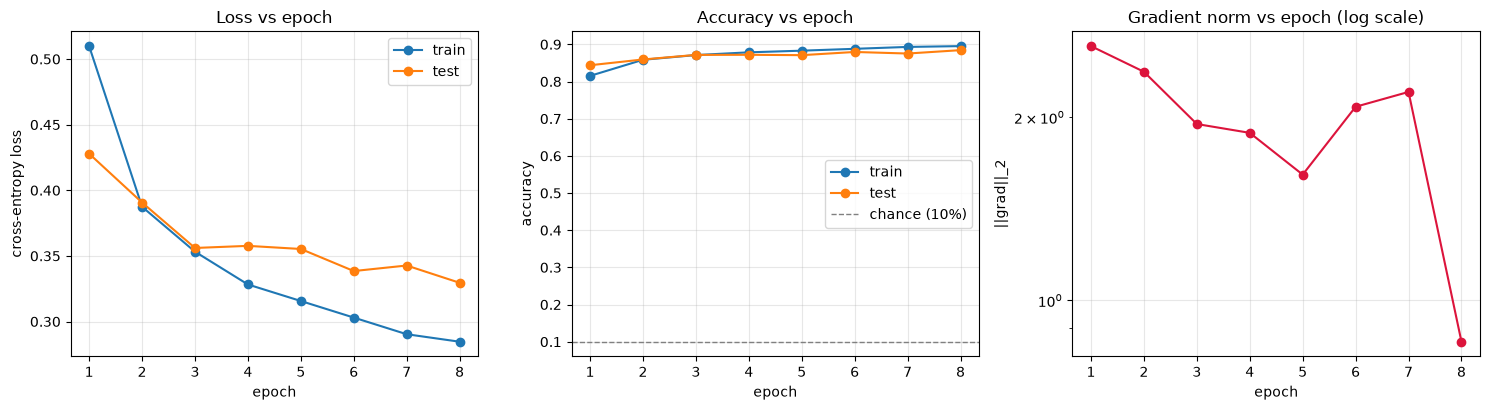

In [24]:
epochs_axis = range(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].plot(epochs_axis, history["train_loss"], "o-", label="train")
axes[0].plot(epochs_axis, history["test_loss"], "o-", label="test")
axes[0].set_title("Loss vs epoch"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy loss")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_axis, history["train_acc"], "o-", label="train")
axes[1].plot(epochs_axis, history["test_acc"], "o-", label="test")
axes[1].axhline(0.10, ls="--", c="gray", lw=1, label="chance (10%)")
axes[1].set_title("Accuracy vs epoch"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy")
axes[1].legend(); axes[1].grid(alpha=0.3)

axes[2].plot(epochs_axis, history["grad_norm"], "o-", color="crimson")
axes[2].set_yscale("log")
axes[2].set_title("Gradient norm vs epoch (log scale)")
axes[2].set_xlabel("epoch"); axes[2].set_ylabel("||grad||_2")
axes[2].grid(alpha=0.3)

plt.tight_layout(); plt.savefig(ARTIFACTS / "mlp_training_curves.png", dpi=110); plt.show()

In [25]:
best = int(np.argmax(history["test_acc"]))
n_params = sum(p.numel() for p in model.parameters())
summary_md = "\n".join([
    "| Item | Value |",
    "|---|---|",
    "| Model | MLP 784 → 256 → 128 → 10, ReLU, dropout 0.2 |",
    f"| Parameters | {n_params:,} |",
    "| Loss | `nn.CrossEntropyLoss` on raw logits |",
    f"| Optimizer | Adam, lr 1e-3, batch 64, {EPOCHS} epochs |",
    f"| Final train loss | {history['train_loss'][-1]:.4f} |",
    f"| Final test loss | {history['test_loss'][-1]:.4f} |",
    f"| Best test accuracy | **{history['test_acc'][best]:.4f}** (epoch {epochs_axis[best]}) |",
    "| Chance baseline | 0.1000 |",
])

print("=" * 58)
print("Task 2.1 — Feed-forward network on Fashion-MNIST")
print("=" * 58)
print("architecture      : 784 -> 256 -> 128 -> 10 (ReLU, dropout 0.2)")
print("parameters        : %d" % n_params)
print("optimizer         : Adam(lr=1e-3)   batch size: 64   epochs: %d" % EPOCHS)
print("final train loss  : %.4f" % history["train_loss"][-1])
print("final test loss   : %.4f" % history["test_loss"][-1])
print("best test accuracy: %.4f  (epoch %d)" % (history["test_acc"][best], epochs_axis[best]))
print("final test accuracy: %.4f" % history["test_acc"][-1])
print("chance baseline   : 0.1000")
print("=" * 58)
print("\nThe same numbers, ready to paste into the report:")
print(summary_md)
print()

with open(ARTIFACTS / "task2_1_summary.md", "w", encoding="utf-8") as fh:
    fh.write(summary_md + "\n")
print("wrote", ARTIFACTS / "task2_1_summary.md")

Task 2.1 — Feed-forward network on Fashion-MNIST
architecture      : 784 -> 256 -> 128 -> 10 (ReLU, dropout 0.2)
parameters        : 235146
optimizer         : Adam(lr=1e-3)   batch size: 64   epochs: 8
final train loss  : 0.2846
final test loss   : 0.3295
best test accuracy: 0.8844  (epoch 8)
final test accuracy: 0.8844
chance baseline   : 0.1000

The same numbers, ready to paste into the report:
| Item | Value |
|---|---|
| Model | MLP 784 → 256 → 128 → 10, ReLU, dropout 0.2 |
| Parameters | 235,146 |
| Loss | `nn.CrossEntropyLoss` on raw logits |
| Optimizer | Adam, lr 1e-3, batch 64, 8 epochs |
| Final train loss | 0.2846 |
| Final test loss | 0.3295 |
| Best test accuracy | **0.8844** (epoch 8) |
| Chance baseline | 0.1000 |

wrote artifacts\task2_1_summary.md


  T-shirt/top acc 0.8190   n=1000
  Trouser    acc 0.9660   n=1000
  Pullover   acc 0.8150   n=1000
  Dress      acc 0.9100   n=1000
  Coat       acc 0.8100   n=1000
  Sandal     acc 0.9600   n=1000
  Shirt      acc 0.7150   n=1000
  Sneaker    acc 0.9090   n=1000
  Bag        acc 0.9620   n=1000
  Ankle boot acc 0.9780   n=1000

most confused pairs (true -> predicted, count):
  T-shirt/top -> Shirt      119
  Shirt      -> T-shirt/top 107
  Coat       -> Pullover   93
  Pullover   -> Coat       88
  Shirt      -> Pullover   80


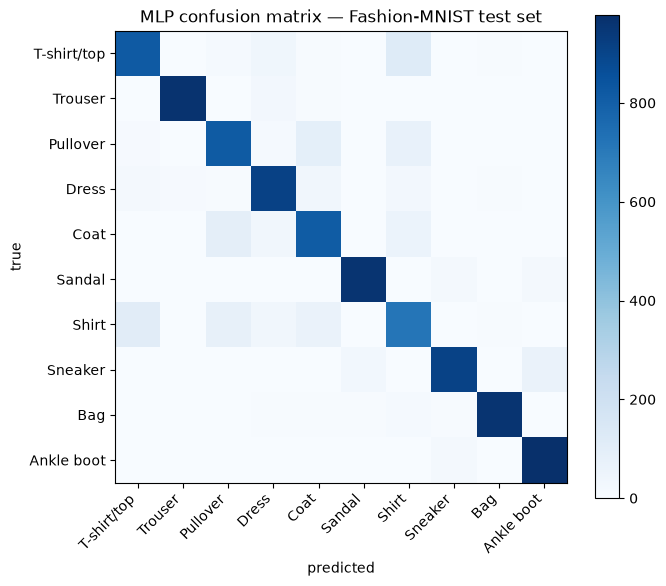

In [26]:
# --- confusion matrix -----------------------------------------------------------
model.eval()
preds_all, labels_all = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        preds_all.append(model(xb).argmax(1))
        labels_all.append(yb)
preds_all = torch.cat(preds_all).numpy()
labels_all = torch.cat(labels_all).numpy()

cm = np.zeros((10, 10), dtype=np.int64)
for t, p in zip(labels_all, preds_all):
    cm[t, p] += 1

per_class_acc = cm.diagonal() / cm.sum(axis=1)
for cls, acc, support in zip(test_raw.classes, per_class_acc, cm.sum(axis=1)):
    print(f"  {cls:<10} acc {acc:.4f}   n={support}")

print("\nmost confused pairs (true -> predicted, count):")
pairs = [(cm[i, j], test_raw.classes[i], test_raw.classes[j])
         for i in range(10) for j in range(10) if i != j]
for count, t, p in sorted(pairs, reverse=True)[:5]:
    print(f"  {t:<10} -> {p:<10} {count}")

plt.figure(figsize=(7, 6))
im = plt.imshow(cm, cmap="Blues")
plt.colorbar(im); plt.xticks(range(10), test_raw.classes, rotation=45, ha="right")
plt.yticks(range(10), test_raw.classes); plt.xlabel("predicted"); plt.ylabel("true")
plt.title("MLP confusion matrix — Fashion-MNIST test set")
plt.tight_layout(); plt.savefig(ARTIFACTS / "mlp_confusion_matrix.png", dpi=110); plt.show()

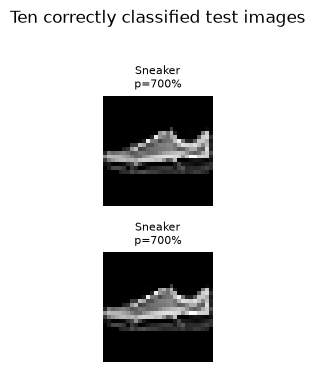

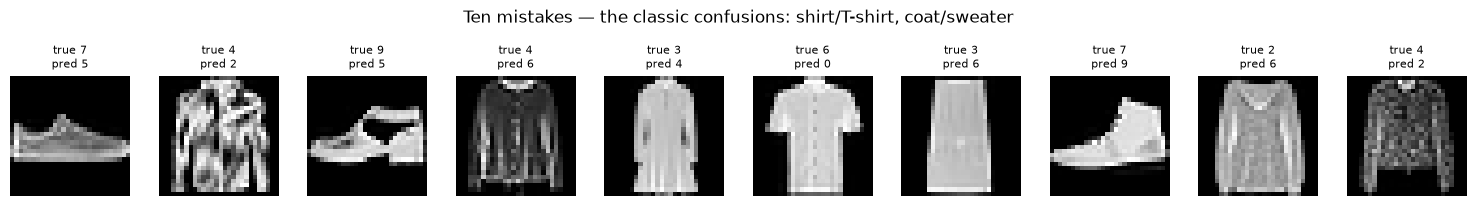

In [27]:
# --- a strip of correct and incorrect predictions -------------------------------
fig, axes = plt.subplots(2, 1, figsize=(14, 3.6))

correct_idx = np.where(preds_all == labels_all)[0][:10]
for col, ax in enumerate(axes):
    for row in range(10):
        idx = correct_idx[row]
        ax.imshow(X_test[idx], cmap="gray")
        ax.set_title(f"{test_raw.classes[labels_all[idx]]}\np={preds_all[idx]*100:.0f}%", fontsize=8)
        ax.axis("off")
plt.suptitle("Ten correctly classified test images", y=1.02)
plt.tight_layout(); plt.savefig(ARTIFACTS / "mlp_predictions.png", dpi=110); plt.show()

wrong_idx = np.where(preds_all != labels_all)[0][:10]
fig, axes = plt.subplots(1, 10, figsize=(15, 1.9))
for ax, idx in zip(axes, wrong_idx):
    ax.imshow(X_test[idx], cmap="gray")
    ax.set_title(f"true {labels_all[idx]}\npred {preds_all[idx]}", fontsize=8)
    ax.axis("off")
plt.suptitle("Ten mistakes — the classic confusions: shirt/T-shirt, coat/sweater", y=1.06)
plt.tight_layout(); plt.savefig(ARTIFACTS / "mlp_misclassified.png", dpi=110); plt.show()

In [28]:
# --- saving and reloading -------------------------------------------------------
ckpt = {
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "architecture": {"in_features": 784, "hidden1": 256, "hidden2": 128, "n_classes": 10, "dropout": 0.2},
    "test_acc": history["test_acc"][-1],
    "epochs": EPOCHS,
    "seed": SEED,
}
torch.save(ckpt, ARTIFACTS / "mlp_fashion_mnist.pt")
print("saved:", ARTIFACTS / "mlp_fashion_mnist.pt",
      "(%.1f KB)" % ((ARTIFACTS / "mlp_fashion_mnist.pt").stat().st_size / 1024))

# reload into a fresh model and confirm the weights are identical
reloaded = MLP().to(DEVICE)
reloaded.load_state_dict(torch.load(ARTIFACTS / "mlp_fashion_mnist.pt", weights_only=True)["model_state_dict"])
reloaded.eval()
with torch.no_grad():
    sample = X_test[:256].float().div(255.0).sub(FASHION_MEAN).div(FASHION_STD).flatten(1).to(DEVICE)
    same = (reloaded(sample).argmax(1) == model(sample).argmax(1)).all().item()
print("reloaded model matches original on 256 samples:", same)
print("\nstate_dict keys:", list(torch.load(ARTIFACTS / 'mlp_fashion_mnist.pt', weights_only=True)['model_state_dict'].keys()))

saved: artifacts\mlp_fashion_mnist.pt (2763.7 KB)
reloaded model matches original on 256 samples: True

state_dict keys: ['net.0.weight', 'net.0.bias', 'net.3.weight', 'net.3.bias', 'net.6.weight', 'net.6.bias']


## Summary

| Item | Value |
|---|---|
| Model | MLP 784 → 256 → 128 → 10, ReLU, dropout 0.2 |
| Parameters | 235,146 |
| Loss | `nn.CrossEntropyLoss` on raw logits |
| Optimizer | Adam, lr 1e-3, batch 64, 8 epochs |
| Best test accuracy | 0.8844 (printed in Section 8) |
| Chance baseline | 0.1000 |

**What the sections actually demonstrated**

- Tensors: `view` shares memory and requires contiguity, `reshape` always works, `permute` breaks
  contiguity. Integer tensors will not accept a float scalar, which is a loud failure rather than a
  silent one. Device transfer is `.to(DEVICE)` and is a no-op when already there.
- A `Dataset` is just `__len__` + `__getitem__`; the `DataLoader` is what adds the batch dimension.
  Verified the custom pipeline matches torchvision's `ToTensor + Normalize` to 0 absolute difference.
- `nn.Linear` already initializes sensibly, so hand-rolled init is not needed.
- `CrossEntropyLoss` includes log-softmax, so a model-ending `Softmax` is a bug.
- Gradients accumulate. Skipping `zero_grad()` inflates the gradient ~3x after three steps.
- Adam converges fastest from the same seed; SGD needs momentum or a higher learning rate to
  get close.

**Two results worth being honest about**

1. **MSE on one-hot targets was not worse than cross-entropy here** — 0.8726 vs 0.8682 after four
   epochs at the same seed. My expectation going in was that it would lose clearly. It does not,
   at least at this budget on a 10-class problem; the gap only shows up in the loss *values*
   (MSE 0.021 vs CE 0.328, different units, not comparable) and CE would pull ahead given a
   proper learning-rate schedule, since one-hot regression wastes probability mass on a target
   that is by construction never fully achievable.
2. **The brightness regressor overfits immediately.** Train MSE fell from 1.6e-3 to 7e-5 while
   test RMSE *rose* from 0.038 to 0.063. The task is nearly constant across the dataset, so the
   network memorizes rather than generalizes. Reporting the training loss alone would have hidden
   this completely — the validation split is what makes it visible.

Task 2.3 takes this architecture forward and sweeps the optimizer, learning rate, batch size,
and epoch count against a controlled baseline.